In [1]:
from matplotlib.gridspec import GridSpec
from matplotlib.backends.backend_pdf import PdfPages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from itertools import product
from load_traces import load_aligned_act, build_intervals,get_tuned_df
from scipy.ndimage import gaussian_filter1d


# Set up

In [2]:
color_map = {
    'Aggressive':        "#fe0806",
    'Pro-Social':        "#55a0fb",
    'Social Avoidance':  "#b856d7",
    'Asocial':            "#e7e6e6",
    'Mixed':                "#4CAF50"}
traces_dir    = '/Users/amonast/Desktop/miniscope/Traces'
behavior_csv  = '/Users/amonast/Desktop/miniscope/data/intervals_allmice.csv'
data_info_csv = '/Users/amonast/Desktop/miniscope/dbnst_data_info.csv'
data_dir      = '/Users/amonast/Desktop/miniscope/data'

animals       = pd.read_csv(data_info_csv)['Mouse'].unique()
tuned_ids,tuned_df = get_tuned_df(animals, data_dir)

# Functions

In [3]:
def n_positive(row):
    try:
        z_row = tuned_df.loc[(row["animal"], row["session"], row["behavior_type"], "zscore")]
    except KeyError:
        return 0
    if not row["tuned_cells"]:
        return 0
    return sum(float(z_row[c]) > 0 for c in row["tuned_cells"])

def n_negative(row):
    try:
        z_row = tuned_df.loc[(row["animal"], row["session"], row["behavior_type"], "zscore")]
    except KeyError:
        return 0
    if not row["tuned_cells"]:
        return 0
    return sum(float(z_row[c]) < 0 for c in row["tuned_cells"])

def proportion_counts(tuned_ids, animal_set, btypes):
    sub = tuned_ids[tuned_ids["animal"].isin(animal_set) & tuned_ids["behavior_type"].isin(btypes)]

    category_counts = {bt: 0 for bt in btypes}
    category_counts["Mixed"] = 0

    for (ani, ses), grp in sub.groupby(["animal", "session"]):
        cell_to_btypes = {}
        for _, row in grp.iterrows():
            for cell in row["tuned_cells"]:
                cell_to_btypes.setdefault(cell, set()).add(row["behavior_type"])

        for cell_btypes in cell_to_btypes.values():
            if len(cell_btypes) > 1:
                category_counts["Mixed"] += 1
            else:
                category_counts[next(iter(cell_btypes))] += 1

    counts = pd.Series(category_counts).reindex(btypes + ["Mixed"], fill_value=0)
    counts = counts[counts > 0]
    return counts / counts.sum()


# Proportions of Tuned Cells

In [4]:
# count tuned cells 
tuned_ids["n_tuned"] = tuned_ids["tuned_cells"].apply(len)

# Which animals displayed aggression (any session) 
agg_animals = set(tuned_ids.loc[(tuned_ids["behavior_type"] == "Aggressive") 
                       & (tuned_ids["n_tuned"] > 0), "animal"])
non_agg_animals = set(tuned_ids["animal"]) - agg_animals
print(f'Aggressive animals:{agg_animals}')
print(f'Not-aggressive animals:{non_agg_animals}')

# - negative and positive modulated cells - 
tuned_ids["n_negative"] = tuned_ids.apply(n_negative, axis=1)
tuned_ids["n_positive"] = tuned_ids.apply(n_positive, axis=1)

social_btypes = ["Pro-Social", "Social Avoidance"]
all_btypes    = ["Pro-Social", "Social Avoidance", "Aggressive"]

props_non_agg = proportion_counts(tuned_ids,non_agg_animals, social_btypes)
props_agg     = proportion_counts(tuned_ids,agg_animals,     all_btypes)

Aggressive animals:{'C3M4', 'C3M2', 'C1F2', 'C3M3'}
Not-aggressive animals:{'C3F3', 'C3F4', 'C2F1', 'C2M4', 'C1M1', 'C1M2'}


In [5]:
props_non_agg

Pro-Social          0.576720
Social Avoidance    0.243386
Mixed               0.179894
dtype: float64

In [24]:
def excit_inhib_proportion(tuned_ids,animal_set, btype):
    """For one behavior type, fraction of tuned cells that are excited vs inhibited."""
    subset = tuned_ids[tuned_ids["animal"].isin(animal_set) & (tuned_ids["behavior_type"] == btype)]
    n_excited  = subset["n_positive"].sum()
    n_inhibited = subset["n_negative"].sum()
    total = n_excited + n_inhibited
    if total == 0:
        return 0.0, 0.0
    return n_excited / total, n_inhibited / total

def nested_pie(tuned_ids,animal_set, btypes, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4), dpi=150)

    exc_colors = {
        'Pro-Social':       "#2F50F5",
        'Social Avoidance': "#823EC6",
        'Aggressive':       "#EE3C3C",
        'Mixed':            "#4CAF50",
    }
    inh_colors = {
        'Pro-Social':       "#528DF4",
        'Social Avoidance': "#A788C4",
        'Aggressive':       "#E7B8B8",
        'Mixed':            "#A5D6A7",
    }

    props = proportion_counts(tuned_ids, animal_set, btypes)

    outer_vals, outer_colors = [], []
    for bt in props.index:
        p = props[bt]
        if bt == "Mixed" or p == 0:
            outer_vals.append(p)
            outer_colors.append(exc_colors[bt])
        else:
            exc, inh = excit_inhib_proportion(tuned_ids,animal_set, bt)
            outer_vals += [p * exc, p * inh]
            outer_colors += [exc_colors[bt], inh_colors[bt]]

    inner_colors = [color_map.get(bt) for bt in props.index]

    ax.pie(outer_vals, radius=1.0, colors=outer_colors,
           wedgeprops=dict(width=0.1, edgecolor='white', linewidth=0.5))
    ax.pie(props.values, radius=0.9, colors=inner_colors,
           wedgeprops=dict(edgecolor='white', linewidth=0.5),
           autopct='%1.0f%%', pctdistance=0.45,
           textprops=dict(fontsize=7, ha='center'))
    return ax


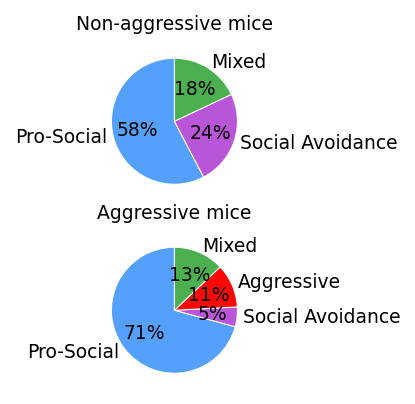

In [25]:
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(8,3),dpi=150)
for ax, props, title in [(ax1, props_non_agg, "Non-aggressive mice"),
                         (ax2, props_agg,     "Aggressive mice"),]:
    colors = [color_map.get(b) for b in props.index]
    ax.pie(props.values,
        labels=props.index,
        colors=colors,
        autopct='%1.0f%%',
        textprops=dict(fontsize=9),
        startangle=90,
        wedgeprops=dict(linewidth=0.5, edgecolor='white'),)
    ax.set_title(title, fontsize=9)
plt.savefig('figures/tuning_pie_chart.svg',transparent=True)

In [55]:
import matplotlib
matplotlib.style.use('paper_style.mplstyle')

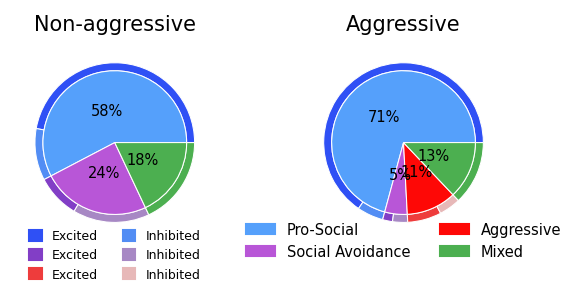

In [57]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4,2), dpi=150)
nested_pie(tuned_ids,non_agg_animals, social_btypes, ax=ax1)
nested_pie(tuned_ids,agg_animals, all_btypes, ax=ax2)
ax1.set_title("Non-aggressive"); ax2.set_title("Aggressive")

legend_handles = [plt.matplotlib.patches.Patch(color=color_map.get(bt), label=bt) 
                  for bt in props.index]
ax2.legend(handles=legend_handles, loc='lower center',
          bbox_to_anchor=(0.5, -0.15), fontsize=7, frameon=False, ncol=2)

btypes_all = ["Pro-Social", "Social Avoidance", "Aggressive"]

handles = (
    [Patch(color=exc_colors[bt], label='Excited')   for bt in btypes_all] +
    [Patch(color=inh_colors[bt], label='Inhibited') for bt in btypes_all]
)

ax1.legend(handles=handles, ncol=2,
           loc='lower center', bbox_to_anchor=(0.5, -0.25),
           fontsize=6, frameon=False, handlelength=1, handleheight=1)

plt.tight_layout()
plt.savefig('figures/piecharts_nested_alltuned.svg',transparent=True)